# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Raihan Nurhakim | 5054251030 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc)

torch.manual_seed(42)
np.random.seed(42)


In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv("Churn_Modelling.csv")

print("Jumlah baris dan kolom:", df.shape)
display(df.head())

print("\nInfo dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe())

print("\nJumlah missing value per kolom:")
print(df.isnull().sum())


Jumlah baris dan kolom: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Info dataset:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB

Statistik deskriptif:


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Jumlah missing value per kolom:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


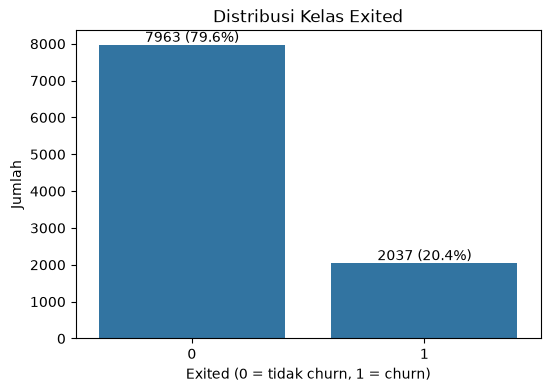

Exited
0    0.796
1    0.204
Name: proportion, dtype: float64


In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Exited", data=df)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)",
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi Kelas Exited")
plt.xlabel("Exited (0 = tidak churn, 1 = churn)")
plt.ylabel("Jumlah")
plt.show()

print(df["Exited"].value_counts(normalize=True).round(3))


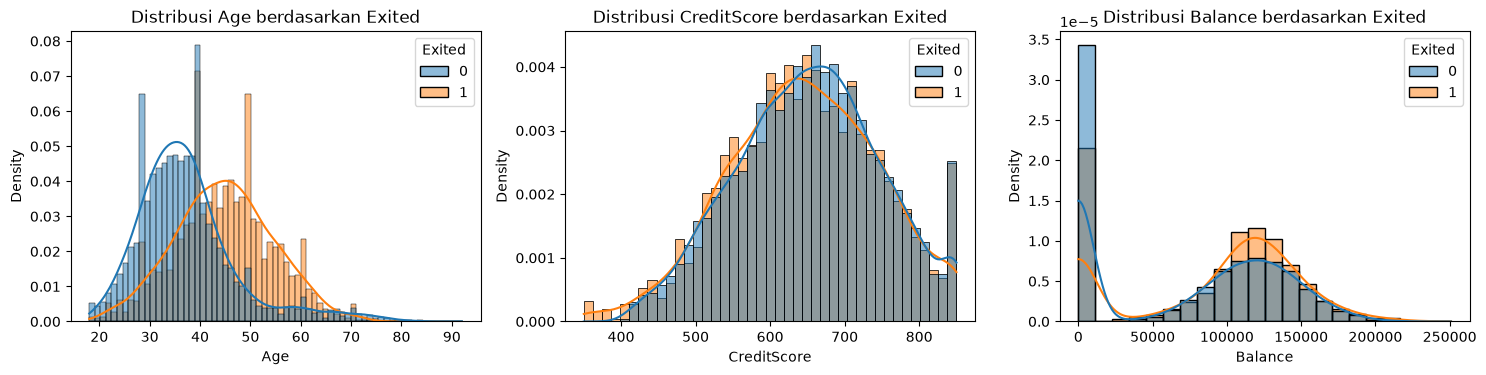

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "CreditScore", "Balance"]):
    sns.histplot(data=df, x=col, hue="Exited", kde=True, stat="density", common_norm=False, ax=ax)
    ax.set_title(f"Distribusi {col} berdasarkan Exited")
plt.tight_layout()
plt.show()


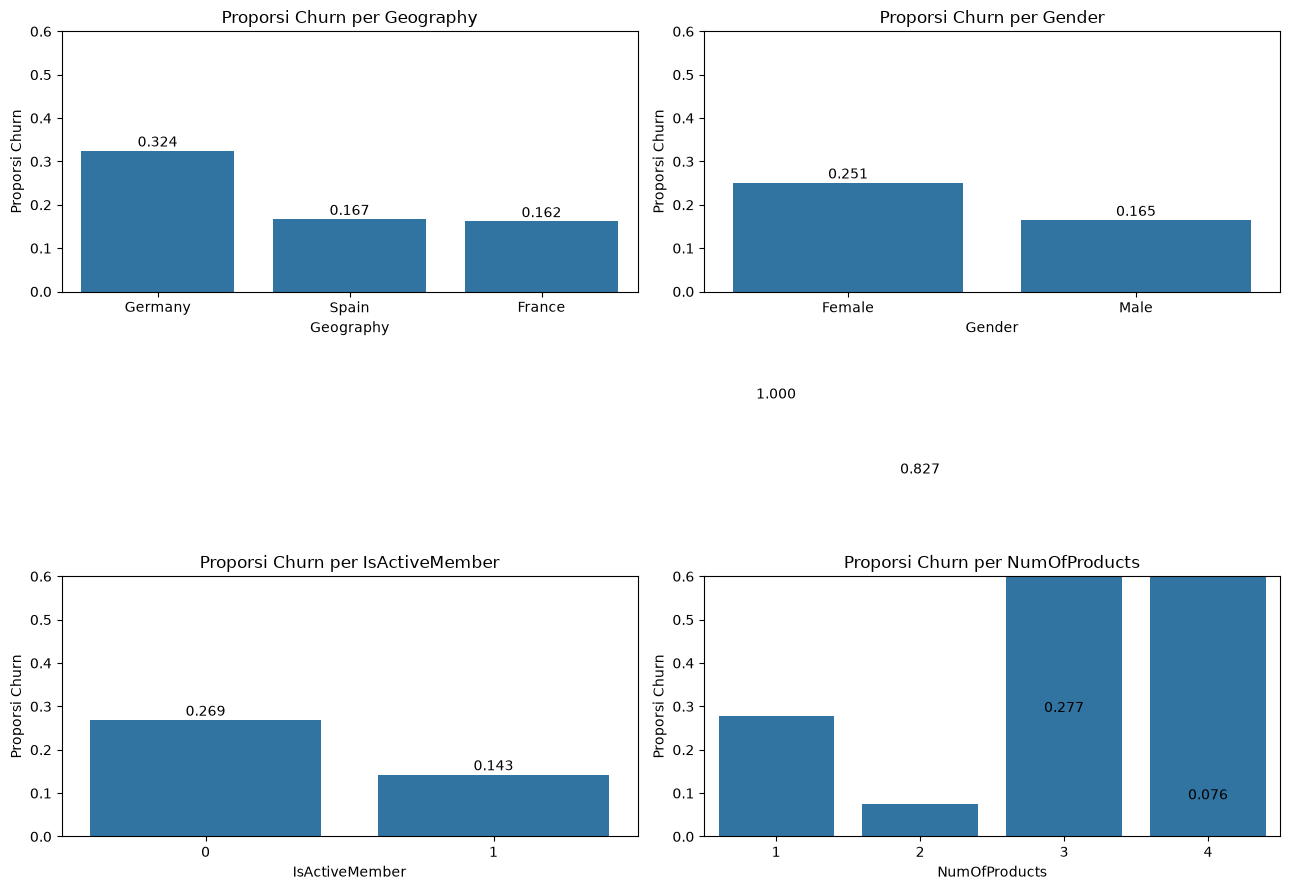

In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]):
    prop = df.groupby(col)["Exited"].mean().sort_values(ascending=False)
    sns.barplot(x=prop.index, y=prop.values, ax=ax)
    ax.set_title(f"Proporsi Churn per {col}")
    ax.set_ylabel("Proporsi Churn")
    ax.set_ylim(0, 0.6)
    for i, v in enumerate(prop.values):
        ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

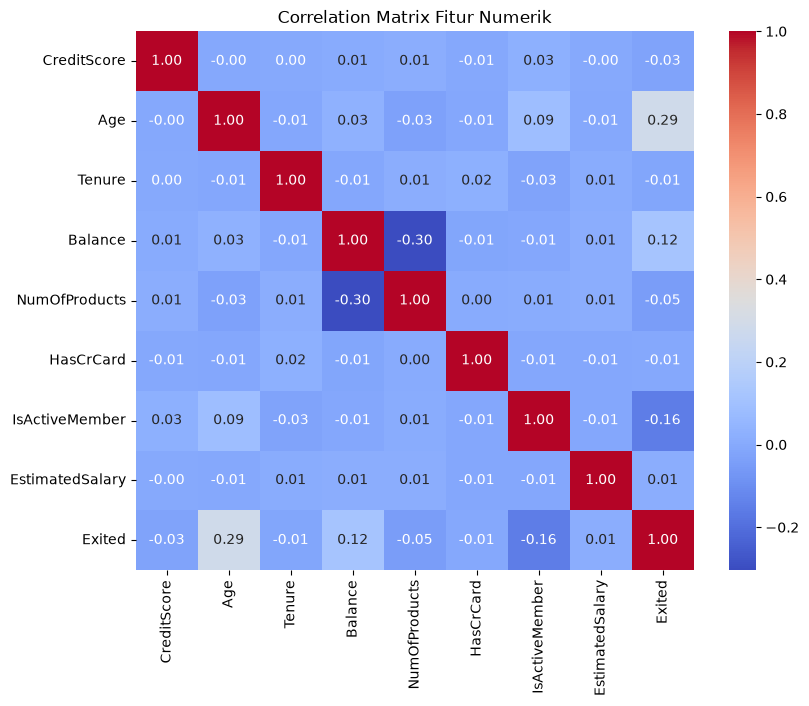

Jumlah Balance = 0: 3617
Rata-rata churn pada Balance = 0 dan > 0:
Balance
False    0.241
True     0.138
Name: Exited, dtype: float64
Jumlah duplikat: 0


In [6]:
# EDA tambahan: cek korelasi antar fitur numerik dan distribusi Balance (banyak nilai 0).
num_cols_eda = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                "HasCrCard", "IsActiveMember", "EstimatedSalary", "Exited"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols_eda].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix Fitur Numerik")
plt.show()

print("Jumlah Balance = 0:", (df["Balance"] == 0).sum())
print("Rata-rata churn pada Balance = 0 dan > 0:")
print(df.groupby(df["Balance"] == 0)["Exited"].mean().round(3))
print("Jumlah duplikat:", df.duplicated().sum())


# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [7]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# RowNumber hanya nomor urut, CustomerId hanya identitas nasabah, dan Surname adalah nama
# yang tidak memiliki hubungan sebab-akibat dengan keputusan churn, sehingga ketiganya di-drop.
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df.head()


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [8]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df.drop(columns=["Exited"])
y = df["Exited"].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print("Train :", X_train.shape, np.bincount(y_train))
print("Val   :", X_val.shape, np.bincount(y_val))
print("Test  :", X_test.shape, np.bincount(y_test))


Train : (7000, 10) [5574 1426]
Val   : (1500, 10) [1194  306]
Test  : (1500, 10) [1195  305]


In [9]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

# Gender kategorikal biner -> encode jadi 0/1 (Male = 1, Female = 0)
for part in (X_train, X_val, X_test):
    part["Gender"] = (part["Gender"] == "Male").astype(int)

num_cols = ["CreditScore", "Age", "Tenure", "Balance",
            "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"]
cat_cols = ["Geography"]
bin_cols = ["Gender"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("bin", "passthrough", bin_cols),
])

X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

print("Bentuk setelah preprocessing:", X_train.shape, X_val.shape, X_test.shape)
print("Nama fitur:", preprocessor.get_feature_names_out())


Bentuk setelah preprocessing: (7000, 12) (1500, 12) (1500, 12)
Nama fitur: ['num__CreditScore' 'num__Age' 'num__Tenure' 'num__Balance'
 'num__NumOfProducts' 'num__HasCrCard' 'num__IsActiveMember'
 'num__EstimatedSalary' 'cat__Geography_France' 'cat__Geography_Germany'
 'cat__Geography_Spain' 'bin__Gender']


In [10]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=64, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=64, shuffle=False)

print(len(train_loader), len(val_loader), len(test_loader))


110 24 24


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [11]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train, y_train)

y_pred_lr = logreg.predict(X_test)
y_prob_lr = logreg.predict_proba(X_test)[:, 1]
print("Selesai melatih Logistic Regression.")


Selesai melatih Logistic Regression.


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [12]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.net(x)


model_ann = ANN(X_train.shape[1])
print(model_ann)
print("Jumlah parameter:", sum(p.numel() for p in model_ann.parameters()))


ANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 225


In [13]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=50):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            preds = (torch.sigmoid(out) >= 0.5).float()
            correct += (preds == yb).sum().item()
            total += xb.size(0)

        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                out = model(xb)
                loss = criterion(out, yb)
                val_loss += loss.item() * xb.size(0)
                preds = (torch.sigmoid(out) >= 0.5).float()
                val_correct += (preds == yb).sum().item()
                val_total += xb.size(0)

        val_loss, val_acc = val_loss / val_total, val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:3d}/{epochs} | "
                f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
                f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    return history


def predict_model(model, loader):
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb)
            probs.extend(torch.sigmoid(out).cpu().numpy().ravel())
            labels.extend(yb.cpu().numpy().ravel())
    return np.array(probs), np.array(labels)


criterion = nn.BCEWithLogitsLoss()
optimizer_ann = torch.optim.Adam(model_ann.parameters(), lr=0.001)
history_ann = train_model(model_ann, train_loader, val_loader,
                        criterion, optimizer_ann, epochs=50)


Epoch   1/50 | train loss 0.5654 acc 0.7836 | val loss 0.5029 acc 0.7960
Epoch  10/50 | train loss 0.3681 acc 0.8497 | val loss 0.3503 acc 0.8547
Epoch  20/50 | train loss 0.3476 acc 0.8573 | val loss 0.3289 acc 0.8627
Epoch  30/50 | train loss 0.3429 acc 0.8584 | val loss 0.3246 acc 0.8640
Epoch  40/50 | train loss 0.3412 acc 0.8573 | val loss 0.3235 acc 0.8593
Epoch  50/50 | train loss 0.3398 acc 0.8579 | val loss 0.3227 acc 0.8620


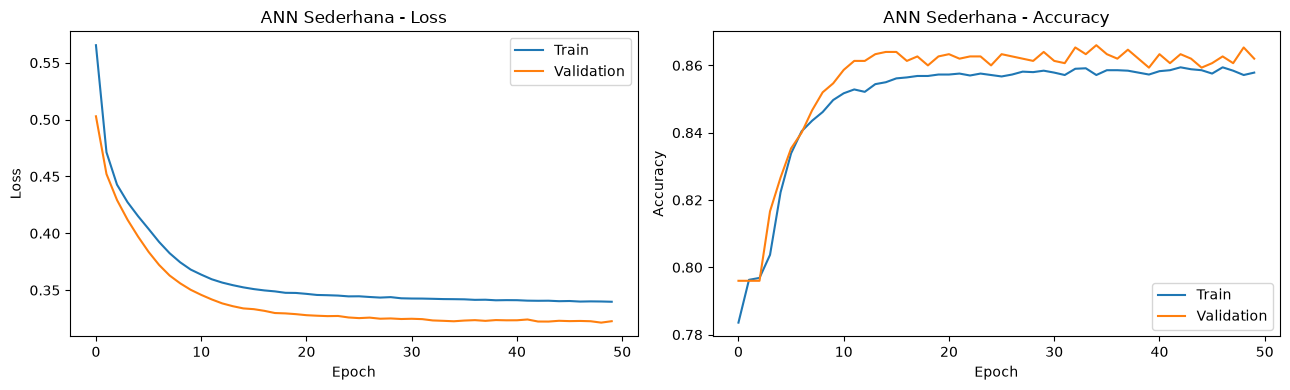

In [14]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

def plot_learning_curve(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"], label="Validation")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


plot_learning_curve(history_ann, "ANN Sederhana")


In [15]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

y_prob_ann, _ = predict_model(model_ann, test_loader)
y_pred_ann = (y_prob_ann >= 0.5).astype(int)
print("Contoh probabilitas:", y_prob_ann[:5].round(3))
print("Contoh label prediksi:", y_pred_ann[:10])


Contoh probabilitas: [0.213 0.016 0.074 0.056 0.203]
Contoh label prediksi: [0 0 0 0 0 0 0 0 0 1]


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [16]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class DeepANN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.net(x)


model_deep = DeepANN(X_train.shape[1])
print(model_deep)
print("Jumlah parameter:", sum(p.numel() for p in model_deep.parameters()))


DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 3457


Epoch   1/50 | train loss 0.5840 acc 0.6693 | val loss 0.4475 acc 0.7960
Epoch  10/50 | train loss 0.3876 acc 0.8477 | val loss 0.3423 acc 0.8587
Epoch  20/50 | train loss 0.3660 acc 0.8543 | val loss 0.3299 acc 0.8580
Epoch  30/50 | train loss 0.3522 acc 0.8577 | val loss 0.3228 acc 0.8627
Epoch  40/50 | train loss 0.3503 acc 0.8614 | val loss 0.3223 acc 0.8667
Epoch  50/50 | train loss 0.3470 acc 0.8630 | val loss 0.3207 acc 0.8660


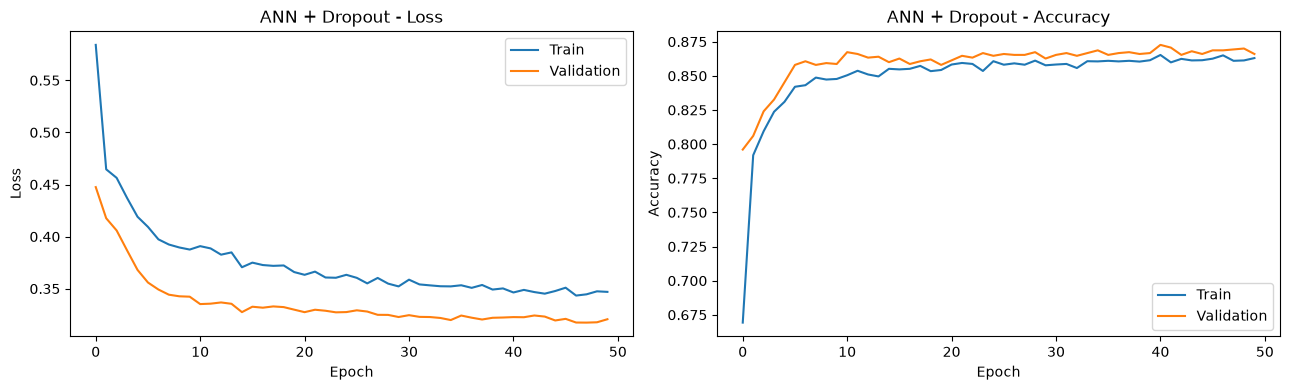

In [17]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

optimizer_deep = torch.optim.Adam(model_deep.parameters(), lr=0.001)
history_deep = train_model(model_deep, train_loader, val_loader,
                           criterion, optimizer_deep, epochs=50)
plot_learning_curve(history_deep, "ANN + Dropout")


In [18]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

y_prob_deep, _ = predict_model(model_deep, test_loader)
y_pred_deep = (y_prob_deep >= 0.5).astype(int)
print("Contoh probabilitas:", y_prob_deep[:5].round(3))
print("Contoh label prediksi:", y_pred_deep[:10])


Contoh probabilitas: [0.174 0.024 0.062 0.103 0.214]
Contoh label prediksi: [0 0 0 0 0 0 0 0 0 1]


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [19]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("pos_weight:", pos_weight)

model_weighted = ANN(X_train.shape[1])
criterion_weighted = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight]))
optimizer_weighted = torch.optim.Adam(model_weighted.parameters(), lr=0.001)
history_weighted = train_model(model_weighted, train_loader, val_loader,
                               criterion_weighted, optimizer_weighted, epochs=50)


pos_weight: 3.908835904628331
Epoch   1/50 | train loss 1.0822 acc 0.4621 | val loss 1.0239 acc 0.6193
Epoch  10/50 | train loss 0.8024 acc 0.7476 | val loss 0.7561 acc 0.7580
Epoch  20/50 | train loss 0.7524 acc 0.7736 | val loss 0.7104 acc 0.7773
Epoch  30/50 | train loss 0.7436 acc 0.7759 | val loss 0.7031 acc 0.7727
Epoch  40/50 | train loss 0.7383 acc 0.7787 | val loss 0.6995 acc 0.7920
Epoch  50/50 | train loss 0.7355 acc 0.7804 | val loss 0.7005 acc 0.7807


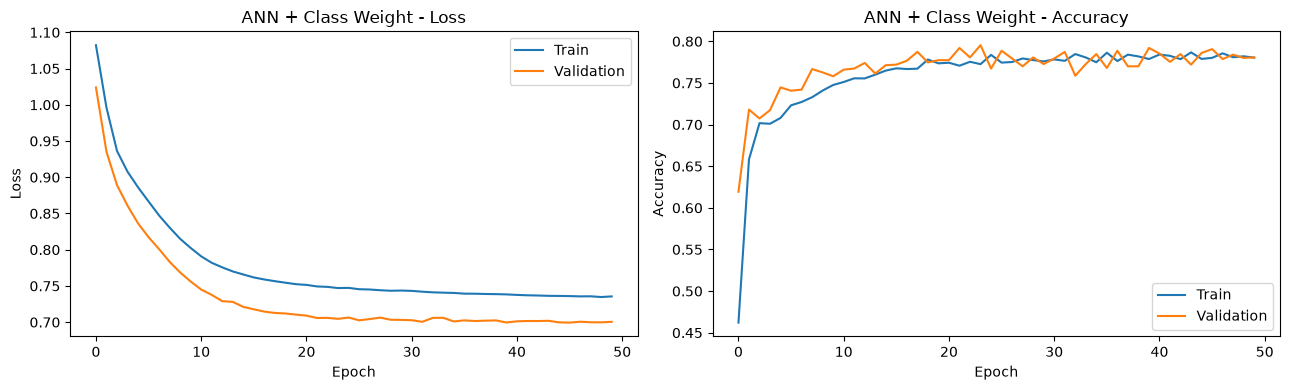

Contoh probabilitas: [0.476 0.098 0.207 0.231 0.451]
Contoh label prediksi: [0 0 0 0 0 0 0 1 1 1]


In [20]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_learning_curve(history_weighted, "ANN + Class Weight")

y_prob_weighted, _ = predict_model(model_weighted, test_loader)
y_pred_weighted = (y_prob_weighted >= 0.5).astype(int)
print("Contoh probabilitas:", y_prob_weighted[:5].round(3))
print("Contoh label prediksi:", y_pred_weighted[:10])


# 4. Evaluasi Model

In [21]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

models_pred = {
    "Logistic Regression": y_pred_lr,
    "ANN Sederhana": y_pred_ann,
    "ANN + Dropout": y_pred_deep,
    "ANN + Class Weight": y_pred_weighted,
}

rows = []
for name, pred in models_pred.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
    })

results_df = pd.DataFrame(rows).set_index("Model").round(4)
results_df


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092
ANN Sederhana,0.8680,0.7861,0.4820,0.5976
ANN + Dropout,0.8647,0.8148,0.4328,0.5653
ANN + Class Weight,0.7933,0.4948,0.7803,0.6056


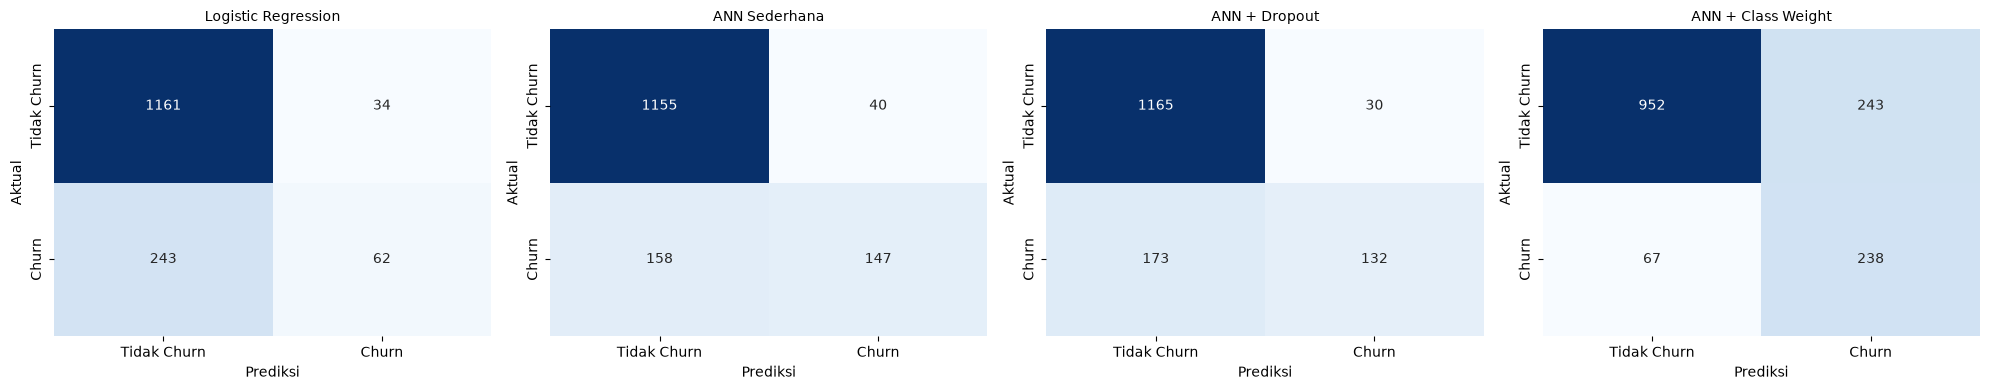

In [22]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, pred) in zip(axes, models_pred.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Tidak Churn", "Churn"],
                yticklabels=["Tidak Churn", "Churn"])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()


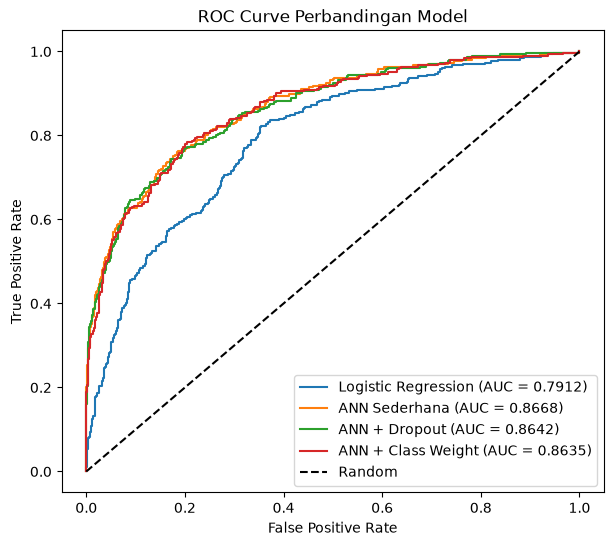

In [23]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

probs_models = {
    "Logistic Regression": y_prob_lr,
    "ANN Sederhana": y_prob_ann,
    "ANN + Dropout": y_prob_deep,
    "ANN + Class Weight": y_prob_weighted,
}

plt.figure(figsize=(7, 6))
for name, prob in probs_models.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Perbandingan Model")
plt.legend(loc="lower right")
plt.show()


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

Dataset Churn Modelling berisi 10.000 baris dan 14 kolom dengan distribusi kelas yang imbalance, yaitu 79,6% nasabah tidak churn dan 20,4% churn. Dari EDA terlihat bahwa nasabah yang churn cenderung lebih tua (Age lebih tinggi), memiliki saldo (Balance) lebih besar, dan proporsi churn jauh lebih tinggi pada nasabah dari Jerman serta pada nasabah dengan `NumOfProducts` = 3 atau 4. Sebanyak 3.617 nasabah memiliki Balance = 0 dan justru memiliki tingkat churn lebih rendah (13,8%) dibanding nasabah dengan saldo positif (24,1%). Temuan ini menunjukkan bahwa Age, Balance, Geography, dan NumOfProducts merupakan fitur yang cukup informatif.

Berdasarkan tabel evaluasi pada test set (1.500 data), Logistic Regression hanya memperoleh Accuracy 0,8153 dengan Precision 0,6458 dan Recall 0,2033 (F1 0,3092). Model ini memang mampu memprediksi kelas mayoritas dengan baik, tetapi hampir tidak pernah menangkap kelas churn. ANN sederhana (1 hidden layer, 225 parameter) meningkatkan performa secara signifikan menjadi Accuracy 0,8680, Precision 0,7861, Recall 0,4820, dan F1 0,5976. Learning curve ANN sederhana menunjukkan train loss dan validation loss yang berdekatan (sekitar 0,340 vs 0,323 pada epoch terakhir) dengan accuracy train 0,8579 dan validation 0,8620, sehingga model tidak menunjukkan overfitting yang berarti; val loss justru sedikit lebih rendah dari train loss karena pengaruh Dropout tidak ada dan evaluasi dilakukan tanpa augmentasi.

ANN yang lebih dalam dengan 3 hidden layer dan Dropout (3.457 parameter) menghasilkan Accuracy 0,8647, Precision 0,8148, Recall 0,4328, dan F1 0,5653. Penambahan layer dan Dropout membuat precision sedikit meningkat, tetapi recall dan F1 justru turun dibanding ANN sederhana. Learning curve-nya juga sangat rapat (train loss 0,3470 vs validation 0,3207; accuracy 0,8630 vs 0,8660), yang menandakan tidak ada overfitting, namun pada dataset tabular yang relatif kecil ini kapasitas tambahan tersebut belum memberi manfaat dan cenderung sedikit underfitting. Dengan kata lain, untuk data ini model yang lebih dalam tidak otomatis lebih baik.

Pada eksperimen class weight, `pos_weight` sebesar 3,91 diberikan pada kelas churn dengan arsitektur ANN sederhana (model terbaik pada 3.2/3.3). Hasilnya, Recall melonjak dari 0,4820 menjadi 0,7803, tetapi Precision turun dari 0,7861 menjadi 0,4948 dan Accuracy turun dari 0,8680 menjadi 0,7933. F1-Score justru sedikit meningkat menjadi 0,6056, nilai tertinggi di antara keempat model. Learning curve model berbobot ini memiliki loss yang lebih tinggi secara absolut karena setiap kesalahan pada kelas minoritas dikalikan bobot, namun selisih train dan validation tetap kecil. Ini menunjukkan trade-off yang khas: class weight berhasil membuat model jauh lebih sensitif terhadap churn (recall tinggi) dengan mengorbankan presisi, sehingga model lebih cocok dipakai jika biaya kehilangan nasabah lebih besar daripada biaya salah menargetkan nasabah yang sebenarnya tidak churn. Secara keseluruhan, ANN sederhana tanpa class weight adalah pilihan paling seimbang untuk accuracy, sedangkan ANN dengan class weight lebih tepat bila tujuan utamanya memaksimalkan deteksi churn karena F1-nya sedikit lebih tinggi.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

Dari eksperimen yang dilakukan, dapat disimpulkan bahwa ANN mengungguli Logistic Regression pada tugas prediksi churn ini. ANN sederhana dengan satu hidden layer memberikan peningkatan Accuracy dari 0,8153 menjadi 0,8680 dan F1-Score dari 0,3092 menjadi 0,5976. Penambahan hidden layer dan Dropout tidak meningkatkan performa pada dataset ini karena model sudah cukup regular dan dataset relatif kecil, sehingga model yang lebih dalam hanya menambah kompleksitas tanpa manfaat yang sebanding. Pemberian class weight melalui `pos_weight` pada `BCEWithLogitsLoss` efektif menaikkan recall kelas churn dari 0,48 menjadi 0,78 dan F1 dari 0,5976 menjadi 0,6056, dengan konsekuensi turunnya precision dari 0,79 menjadi 0,49; keputusan memakai model ini bergantung pada prioritas bisnis.

Saran untuk eksperimen selanjutnya adalah 
- melakukan tuning hyperparameter seperti jumlah neuron, learning rate, dropout rate, dan jumlah epoch dengan validation set
- coba strategi penanganan imbalanced lain seperti SMOTE, undersampling, atau penyesuaian threshold klasifikasi, lalu bandingkan kurva precision-recall-nya
- lakukan feature engineering, misalnya mengelompokkan Age atau Balance, karena EDA menunjukkan pola churn yang cukup jelas pada fitur tersebut
- gunakan cross-validation agar estimasi performa lebih stabil. Untuk penggunaan nyata, threshold 0,5 dapat diturunkan bila tujuan utamanya adalah menangkap sebanyak mungkin nasabah yang berpotensi churn.